# make some plots using the computed healthscore and the training data
### The healthscore can be found in the experiment folder for whichever run created the score, while the training data will be saved as a dataframe in the "experiments" directory and will have a name generated by combining the name of the original file and the proportion of encounters with data (which is used to decide which features to use)

In [40]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
training_data_filename = "combined_hourly_features_phoenix_sepsis_prop_0.8.parquet"

experiments_dir = "/home/jake/Documents/AI_Clinician/experiments"
training_data_path = Path(experiments_dir) / training_data_filename

print(f"Loading training data from {training_data_path}")

training_data = pd.read_parquet(training_data_path)
training_data.head()

Loading training data from /home/jake/Documents/AI_Clinician/experiments/combined_hourly_features_phoenix_sepsis_prop_0.8.parquet


,MASKED_ENCNTR_ID,EVENT_END_DT_TM,airway_type,breath_sequence,control_variable,expiratory_pressure,fio2,mean_airway_pressure,mode_of_ventilation,nitric_oxide,...,temperature,vis,age,mortality,sex,white,black,hispanic,asian,other
0,1165293630,2239-06-12 00:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.400000,0.0,0.0,0.0,1.0,0,0,0,1,0
1,1165293630,2239-06-12 01:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.433333,0.0,0.0,0.0,1.0,0,0,0,1,0
2,1165293630,2239-06-12 02:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.466667,0.0,0.0,0.0,1.0,0,0,0,1,0
3,1165293630,2239-06-12 03:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.500000,0.0,0.0,0.0,1.0,0,0,0,1,0
4,1165293630,2239-06-12 04:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.450000,0.0,0.0,0.0,1.0,0,0,0,1,0


In [16]:
experiment_type = "xgbclassifier_discharge_mortality_choc_grid_search"
date_time = "20250814_185430"

file_name = "all_predictions.parquet"
file_path = Path(experiments_dir) / experiment_type / date_time / file_name

print(f"Loading predictions from {file_path}")

predictions_df = pd.read_parquet(file_path)
predictions_df.head()

Loading predictions from /home/jake/Documents/AI_Clinician/experiments/xgbclassifier_discharge_mortality_choc_grid_search/20250814_185430/all_predictions.parquet


,encounter_id,time,true_label,predicted_label,predicted_proba,predicted_proba_class_0,predicted_proba_class_1,predicted_proba_class_2,health_score
0,1165293630,2239-06-12 00:00:00,1.0,1,0.920882,0.021796,0.920882,0.057322,1.035526
1,1165293630,2239-06-12 01:00:00,1.0,1,0.922010,0.021912,0.922010,0.056078,1.034166
2,1165293630,2239-06-12 02:00:00,1.0,1,0.913959,0.024109,0.913959,0.061932,1.037823
3,1165293630,2239-06-12 03:00:00,1.0,1,0.914117,0.023559,0.914117,0.062324,1.038765
4,1165293630,2239-06-12 04:00:00,1.0,1,0.920695,0.021076,0.920695,0.058229,1.037153


In [17]:
# confirm they are the same length
print(f"Training data length: {len(training_data)}")
print(f"Predictions data length: {len(predictions_df)}")

if len(training_data) != len(predictions_df):
    raise ValueError("Training data and predictions data have different lengths")

Training data length: 2878190
Predictions data length: 2878190


In [18]:
# list the columns in training_data
print("Training data columns:")
print(training_data.columns)

Training data columns:
Index(['MASKED_ENCNTR_ID', 'EVENT_END_DT_TM', 'airway_type', 'breath_sequence',
       'control_variable', 'expiratory_pressure', 'fio2',
       'mean_airway_pressure', 'mode_of_ventilation', 'nitric_oxide',
       'oxygen_flow', 'peep', 'pip', 'weight_kg', 'ecls_support_type',
       'on_ecls', 'cisatracurium', 'furosemide', 'hydralazine', 'labetalol',
       'nitroglycerin', 'nitroprusside', 'intake', 'alt', 'calcium',
       'chloride', 'creatinine', 'crp', 'hematocrit', 'hemoglobin',
       'neutrophil_count', 'neutrophil_percent', 'potassium', 'random_glucose',
       'sodium', 'white_blood_cell_count', 'fixed_pupils',
       'pupil_reaction_left_binary', 'pupil_reaction_right_binary',
       'chloral_hydrate', 'chlorothiazide', 'dexamethasone', 'dobutamine_dose',
       'furosemide_med', 'hydrocortisone', 'methylprednisolone', 'metolazone',
       'prednisolone', 'spironolactone', 'cisatracurium_med', 'clonidine_med',
       'dexmedetomidine_infusion', 'dex

In [33]:
training_features_to_use = [

    'fio2', 'mean_airway_pressure', 'airway_type', 'oxygen_flow',
    
    'random_glucose', 'calcium', 'potassium', 'crp', 'white_blood_cell_count', 'creatinine', 'neutrophil_percent',
    
    'blood_pressure_systolic', 'blood_pressure_diastolic', 'heart_rate', 'temperature', 'oxygen_saturation', 'respiratory_rate', 

    'vis'
]
print(f"{len(training_features_to_use)} features to use:")
print(training_features_to_use)

18 features to use:
['fio2', 'mean_airway_pressure', 'airway_type', 'oxygen_flow', 'random_glucose', 'calcium', 'potassium', 'crp', 'white_blood_cell_count', 'creatinine', 'neutrophil_percent', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'heart_rate', 'temperature', 'oxygen_saturation', 'respiratory_rate', 'vis']


In [ ]:
# create a list of the MASKED_ENCNTR_ID that have non-zero values for vis
masked_encntr_ids = training_data[training_data['vis'] > 0]['MASKED_ENCNTR_ID'].unique().tolist()
print(f"Number of MASKED_ENCNTR_IDs with non-zero VIS: {len(masked_encntr_ids)}")

Number of MASKED_ENCNTR_IDs with non-zero VIS: 1208


In [53]:
encounter_id = masked_encntr_ids[0]
print(f"Using example encounter ID: {encounter_id}")

# training featrues 
example_training_traj = training_data[training_data['MASKED_ENCNTR_ID'] == encounter_id]
example_training_traj = example_training_traj[training_features_to_use]
print(f"Training trajectory shape: {example_training_traj.shape}")

# health score
example_health_score_traj = predictions_df[predictions_df['encounter_id'] == encounter_id]
health_score = example_health_score_traj['health_score'].values

print(f"Health score length: {len(health_score)}")


Using example encounter ID: 1165397252
Training trajectory shape: (4165, 18)
Health score length: 4165


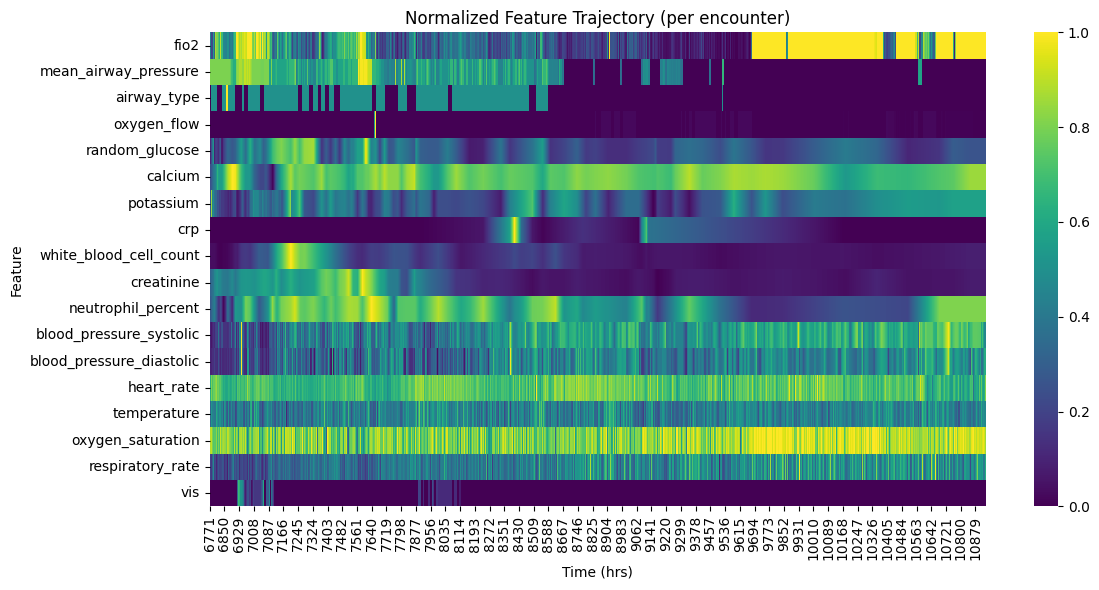

In [52]:
# 1. Min-max normalize each feature
normalized_traj = (example_training_traj - example_training_traj.min()) / (example_training_traj.max() - example_training_traj.min())

# 2. Transpose so features are rows, timepoints are columns
heatmap_data = normalized_traj.T


# 3. Plot heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data, cmap='viridis', cbar=True)
plt.xlabel("Time (hrs)")
plt.ylabel("Feature")
plt.title("Normalized Feature Trajectory (per encounter)")
plt.tight_layout()
plt.show()